In [34]:
# Intentionally left blank. Run the final plotting cell only.


Last token (last layer, rel depth=1.000)
  CKA: 0.0595 +- 0.0011
  II English->Italian: 0.8527 +- 0.0113
  II Italian->English: 0.8956 +- 0.0232
  Neighborhood overlap: 0.0306 +- 0.0020

Averaged representation (last layer, rel depth=1.000)
  CKA: 0.3126 +- 0.0025
  II English->Italian: 0.3443 +- 0.0164
  II Italian->English: 0.4394 +- 0.0153
  Neighborhood overlap: 0.1389 +- 0.0047

Concatenated representation (last layer, rel depth=1.000)
  CKA: 0.4250 +- 0.0031
  II English->Italian: 0.6992 +- 0.0150
  II Italian->English: 0.7841 +- 0.0324
  Neighborhood overlap: 0.0354 +- 0.0034



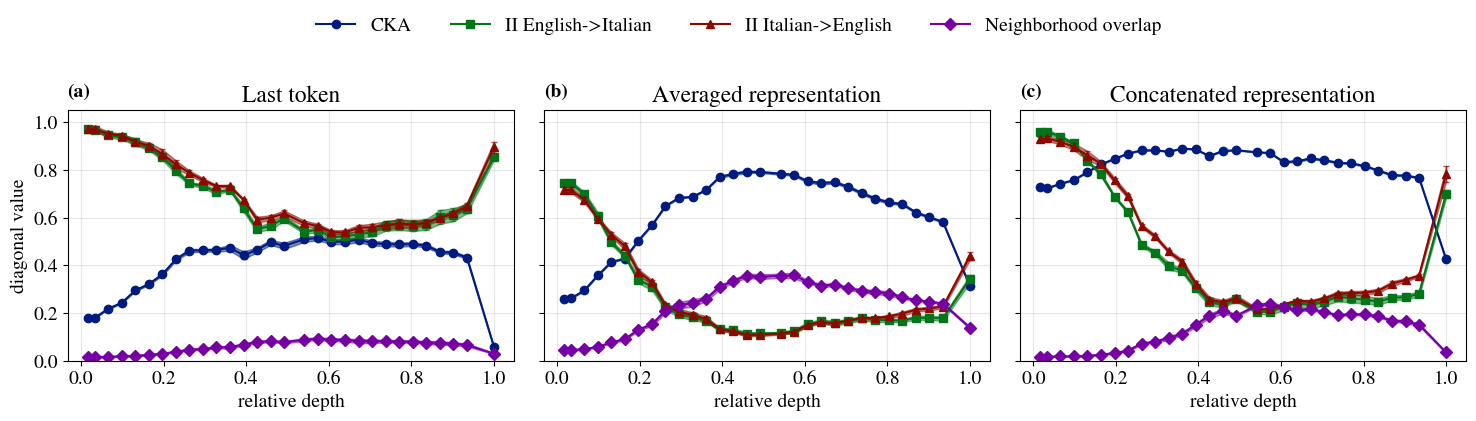

In [35]:
import glob
import re
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils import depths
from utils_plots import apply_plot_style, get_layers

colors, markers, _linestyles = apply_plot_style()

cfg = {
    'modelA': 'deepseek',
    'modelB': 'deepseek',
    'model_for_depth': 'deepseek',
    'aux_A': 'source',
    'aux_B': 'target',
    'languageA': 'english',
    'languageB': 'italian',
    'batch_shuffle': 0,
    'min_token_length': 35,
    'mask': 2,
    'Nbits': 0,
}

base_cka = '../results/CKA'
base_ii = '../results/santiago'
n_files_cka = 100
n_files_ii = 500
k_ii = 10

panels = [
    {'title': 'Last token', 'n_tokens': 1, 'avg_tokens': 0},
    {'title': 'Averaged representation', 'n_tokens': 20, 'avg_tokens': 1},
    {'title': 'Concatenated representation', 'n_tokens': 20, 'avg_tokens': 0},
]


def extract_seed(path):
    m = re.search(r'/seed_(\d+)/', path)
    return int(m.group(1)) if m else -1


def load_diag_series(pattern):
    paths = sorted(glob.glob(pattern))
    assert len(paths) > 0, f'No files found for pattern:\n{pattern}'
    mats = [np.load(p) for p in paths]
    diags = np.stack([m.diagonal() for m in mats], axis=0)
    seeds = [extract_seed(p) for p in paths]
    return {
        'paths': paths,
        'seeds': seeds,
        'mean': diags.mean(axis=0),
        'std': diags.std(axis=0),
    }


def build_prefix(base, n_files, include_k=False):
    prefix = (
        f"{base}/batch_shuffle_{cfg['batch_shuffle']}/"
        f"modelA_{cfg['modelA']}/modelB_{cfg['modelB']}/"
        f"aux_A_{cfg['aux_A']}/aux_B_{cfg['aux_B']}/"
        f"n_files_{n_files}/min_token_length_{cfg['min_token_length']}/"
        f"languageA_{cfg['languageA']}/languageB_{cfg['languageB']}/"
        f"mask_{cfg['mask']}/"
    )
    if include_k:
        prefix += f'k_{k_ii}/'
    prefix += f"Nbits_{cfg['Nbits']}/seed_*/"
    return prefix


def load_all_metrics(n_tokens, avg_tokens):
    pattern_cka = (
        build_prefix(base_cka, n_files_cka)
        + f"n_tokens_{n_tokens}_avg_{avg_tokens}_cka.npy"
    )
    pattern_ii_ab = (
        build_prefix(base_ii, n_files_ii, include_k=True)
        + f"n_tokens_{n_tokens}_avg_{avg_tokens}_AB.npy"
    )
    pattern_ii_ba = (
        build_prefix(base_ii, n_files_ii, include_k=True)
        + f"n_tokens_{n_tokens}_avg_{avg_tokens}_BA.npy"
    )
    pattern_overlap = (
        build_prefix(base_ii, n_files_ii, include_k=True)
        + f"n_tokens_{n_tokens}_avg_{avg_tokens}_alignment.npy"
    )
    return {
        'cka': load_diag_series(pattern_cka),
        'ii_ab': load_diag_series(pattern_ii_ab),
        'ii_ba': load_diag_series(pattern_ii_ba),
        'overlap': load_diag_series(pattern_overlap),
    }


def plot_with_band(ax, xvals, stat, color, marker, label):
    ax.plot(xvals, stat['mean'], color=color, marker=marker, label=label)
    ax.fill_between(
        xvals,
        stat['mean'] - stat['std'],
        stat['mean'] + stat['std'],
        color=color,
        alpha=0.5,
    )
    ax.errorbar(
        xvals,
        stat['mean'],
        yerr=stat['std'],
        fmt='none',
        ecolor=color,
        elinewidth=1.0,
        capsize=2,
        alpha=0.7,
    )


layers = get_layers(cfg['model_for_depth'], depths)
x = layers / depths[cfg['model_for_depth']]

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.0), sharey=True)
panel_labels = ['a', 'b', 'c']
label_ab = f"II {cfg['languageA'].capitalize()}->{cfg['languageB'].capitalize()}"
label_ba = f"II {cfg['languageB'].capitalize()}->{cfg['languageA'].capitalize()}"

for idx, panel in enumerate(panels):
    ax = axes[idx]
    stats = load_all_metrics(panel['n_tokens'], panel['avg_tokens'])

    last_idx = -1
    print(f"{panel['title']} (last layer, rel depth={x[last_idx]:.3f})")
    print(f"  CKA: {stats['cka']['mean'][last_idx]:.4f} +- {stats['cka']['std'][last_idx]:.4f}")
    print(f"  {label_ab}: {stats['ii_ab']['mean'][last_idx]:.4f} +- {stats['ii_ab']['std'][last_idx]:.4f}")
    print(f"  {label_ba}: {stats['ii_ba']['mean'][last_idx]:.4f} +- {stats['ii_ba']['std'][last_idx]:.4f}")
    print(f"  Neighborhood overlap: {stats['overlap']['mean'][last_idx]:.4f} +- {stats['overlap']['std'][last_idx]:.4f}")
    print()

    plot_with_band(ax, x, stats['cka'], colors[0], 'o', 'CKA')
    plot_with_band(ax, x, stats['ii_ab'], colors[1], 's', label_ab)
    plot_with_band(ax, x, stats['ii_ba'], colors[2], '^', label_ba)
    plot_with_band(ax, x, stats['overlap'], colors[3], 'D', 'Neighborhood overlap')

    ax.set_title(panel['title'])
    ax.text(0.0, 1.04, f"({panel_labels[idx]})", transform=ax.transAxes, ha='left', va='bottom', fontweight='bold', clip_on=False)
    ax.set_xlabel('relative depth')
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('diagonal value')
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig('../results/figs/CKA-NO-translations.pdf', bbox_inches='tight')
plt.show()
